# Assignment 1: Machine Learning Classification
**Part A:** Iris dataset (multiclass)  
**Part B:** Heart Disease dataset (binary, OneHotEncoder pipeline)

Run cells top to bottom.

## Part A: Iris Classification

In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42

In [126]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='species')
print(X.shape, '| classes:', list(iris.target_names))
print('Missing values:', X.isna().sum().sum())
print(y.value_counts().sort_index())
X.describe()

(150, 4) | classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Missing values: 0
species
0    50
1    50
2    50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


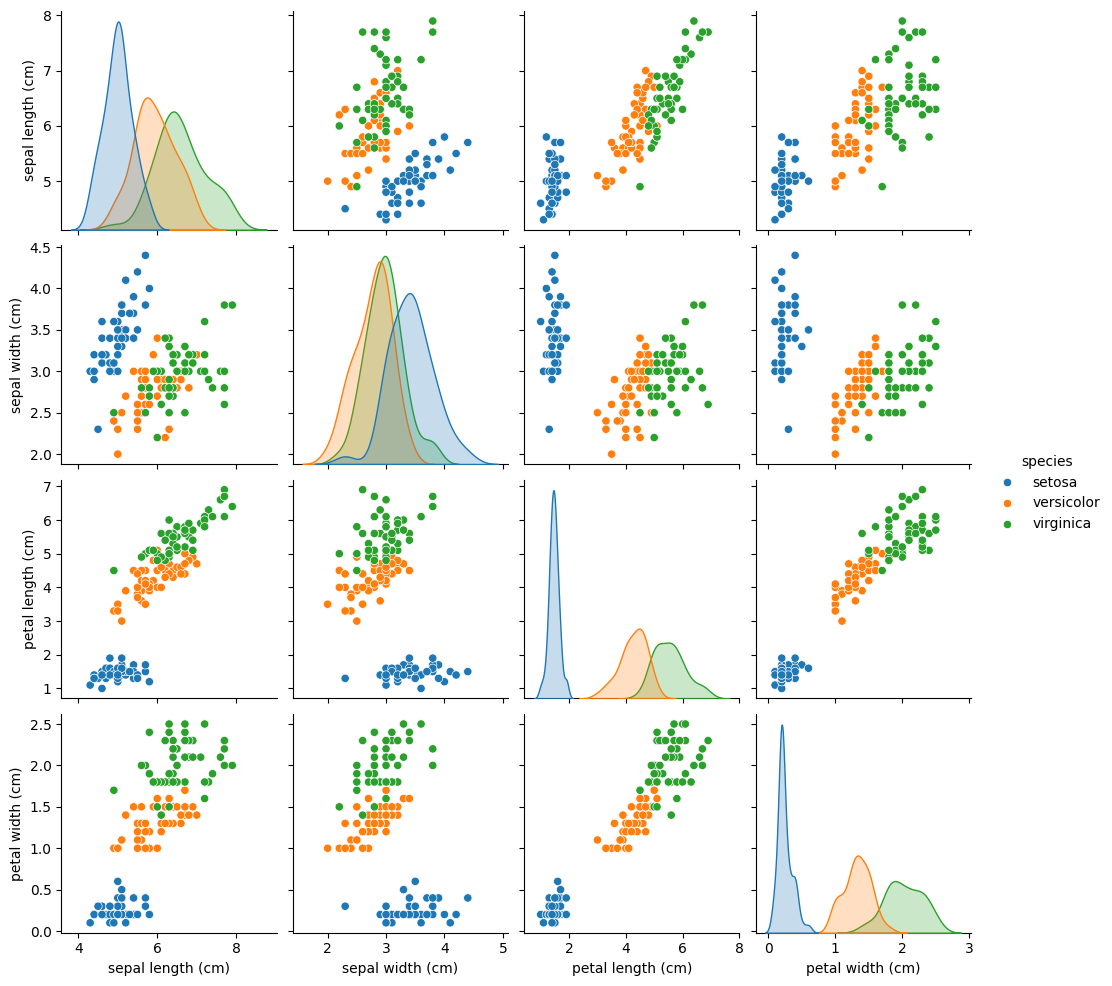

In [127]:
sns.pairplot(pd.concat([X, y.map(dict(enumerate(iris.target_names)))], axis=1), hue='species')
plt.show()

In [128]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

iris_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
iris_model.fit(X_train, y_train)
y_pred = iris_model.predict(X_test)

In [129]:
print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
for avg in ['macro', 'weighted']:
    print(f'Precision ({avg}):', round(precision_score(y_test, y_pred, average=avg), 4))
    print(f'Recall    ({avg}):', round(recall_score(y_test, y_pred, average=avg), 4))
    print(f'F1-score  ({avg}):', round(f1_score(y_test, y_pred, average=avg), 4))
print()
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy : 0.9
Precision (macro): 0.9024
Recall    (macro): 0.9
F1-score  (macro): 0.8997
Precision (weighted): 0.9024
Recall    (weighted): 0.9
F1-score  (weighted): 0.8997

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



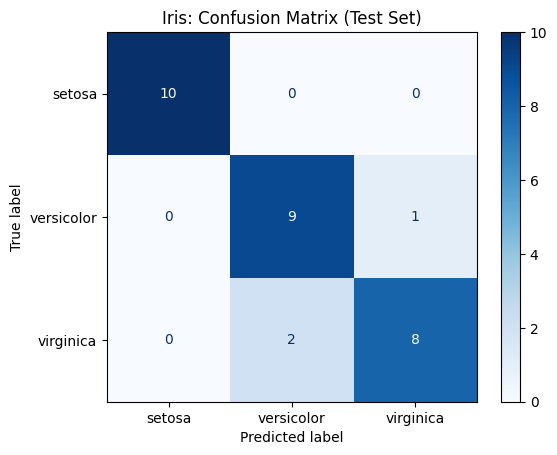

In [130]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(cmap='Blues')
plt.title('Iris: Confusion Matrix (Test Set)')
plt.show()

5-fold CV accuracy: [1.    0.967 0.933 1.    0.9  ] | mean = 0.96 | std = 0.0389


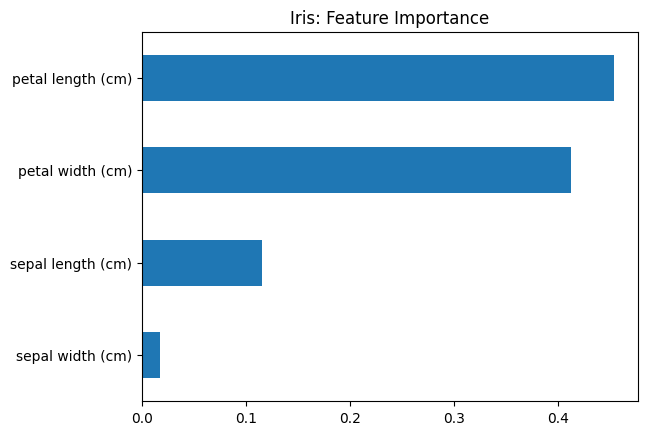

In [131]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv = cross_val_score(iris_model, X, y, cv=skf, scoring='accuracy')
print('5-fold CV accuracy:', cv.round(3), '| mean =', cv.mean().round(4), '| std =', cv.std().round(4))

imp = pd.Series(iris_model.feature_importances_, index=iris.feature_names).sort_values()
imp.plot(kind='barh', title='Iris: Feature Importance')
plt.show()

### Create the heart disease data file
This cell writes `heart_disease.csv` for you, so no upload is needed. Run it once before the Part B cells.

In [132]:
%%writefile heart_disease.csv
age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
68,Male,105,191,38,Yes,Yes,0,No,2,0
58,Female,97,249,22,Yes,Yes,0,No,4,0
44,Female,93,190,23.2,No,Yes,0,No,8,0
72,Male,93,183,39.4,No,No,3,Yes,1,0
37,Female,145,166,22,No,Yes,4,Yes,1,0
50,Male,114,271,36.8,Yes,No,2,Yes,5,0
68,Male,156,225,28.8,No,Yes,1,No,5,1
48,Female,156,236,23.4,Yes,No,3,Yes,1,1
52,Female,116,266,37.2,No,Yes,2,No,6,1
40,Male,121,255,27.8,No,No,4,Yes,1,0
40,Male,139,235,29.3,No,Yes,0,Yes,5,1
53,Male,150,176,25.9,No,No,4,No,9,0
65,Female,140,206,31,Yes,No,1,No,5,0
69,Male,108,180,21.6,Yes,No,3,Yes,6,0
53,Male,110,283,26.6,No,No,3,Yes,8,1
32,Male,94,247,39.3,Yes,No,1,No,1,1
51,Female,171,161,23.7,No,No,2,Yes,2,1
31,Male,131,202,32.4,No,Yes,2,Yes,9,1
53,Male,150,287,25.2,No,No,3,No,3,1
73,Female,111,294,35,No,Yes,3,Yes,6,0
59,Male,110,271,20.9,Yes,Yes,0,No,5,0
67,Male,159,195,39.3,No,Yes,2,Yes,2,0
31,Female,90,213,28,No,Yes,1,No,7,0
50,Male,94,279,23.2,Yes,Yes,2,Yes,4,1
62,Female,101,203,19.6,No,No,0,No,1,0
41,Female,179,256,21.7,No,No,3,Yes,4,0
51,Male,135,200,29.4,No,No,3,No,6,1
73,Male,123,185,25.4,Yes,Yes,0,Yes,7,0
54,Male,138,264,36.2,No,No,1,Yes,7,1
78,Male,167,175,27.5,Yes,No,3,Yes,7,0
56,Female,179,178,23.5,No,No,4,Yes,3,0
71,Male,134,298,31.6,No,No,3,Yes,6,1
57,Female,116,160,33.5,Yes,No,4,Yes,8,0
45,Male,162,189,21.7,No,Yes,0,Yes,4,0
44,Male,115,160,21.7,No,No,0,Yes,8,0
76,Male,136,262,18.8,Yes,Yes,3,Yes,2,1
73,Female,175,188,34.2,Yes,Yes,2,No,9,0
32,Male,145,203,32.6,Yes,Yes,4,No,9,1
66,Male,152,247,28.4,Yes,Yes,1,Yes,8,1
36,Male,137,204,36.6,Yes,Yes,3,No,1,1
50,Male,150,260,35.7,No,No,1,Yes,2,0
38,Female,170,299,30.9,Yes,No,3,Yes,6,0
68,Male,115,218,37.1,No,No,2,No,5,0
47,Female,125,205,22.5,No,Yes,2,Yes,9,0
33,Female,90,182,20.5,No,No,2,Yes,5,1
54,Female,97,185,23.9,Yes,No,2,No,2,1
43,Female,141,297,19.3,Yes,Yes,0,No,4,1
79,Female,168,230,29.7,No,Yes,0,Yes,9,1
38,Female,136,258,38.6,Yes,Yes,4,No,1,1
55,Male,145,222,18.9,Yes,Yes,1,No,1,1
31,Female,175,189,20.7,Yes,No,3,Yes,7,1
49,Female,103,166,27.9,Yes,Yes,3,No,3,1
57,Female,179,278,38.5,No,Yes,0,No,2,1
76,Male,117,210,25,No,No,3,Yes,9,1
36,Male,176,253,29.2,Yes,No,0,No,3,0
73,Female,167,191,18.9,No,Yes,4,No,2,0
37,Male,177,174,21.3,Yes,No,1,Yes,8,0
76,Female,91,188,39.7,Yes,Yes,4,Yes,6,1
64,Female,115,184,39.2,No,Yes,2,Yes,6,1
43,Male,103,280,18.1,No,No,2,No,7,0
46,Female,148,257,38.9,No,No,2,Yes,7,1
65,Male,145,251,32.1,Yes,Yes,4,Yes,6,1
79,Male,96,247,37.1,No,Yes,3,No,4,1
69,Female,92,161,28,Yes,Yes,1,Yes,9,1
33,Female,112,168,29.3,No,No,2,Yes,6,1
31,Male,107,250,28.8,No,Yes,2,Yes,4,1
35,Female,127,193,32.7,Yes,Yes,2,Yes,3,0
71,Female,104,198,21.1,Yes,Yes,1,No,4,1
33,Female,153,166,18.7,Yes,Yes,2,Yes,3,1
58,Male,178,223,24.8,Yes,Yes,1,Yes,2,0
47,Male,117,206,33.5,Yes,No,2,No,5,1
55,Female,163,204,22.4,Yes,Yes,4,Yes,2,1
73,Male,128,196,32.8,Yes,Yes,4,No,6,0
63,Male,146,161,39.3,Yes,Yes,1,No,3,1
39,Male,106,211,20.1,No,Yes,4,No,6,1
65,Male,175,229,32.8,Yes,No,1,Yes,9,1
43,Male,179,232,27.8,Yes,No,4,No,1,1
60,Female,133,157,37.1,No,No,4,No,6,0
77,Female,114,298,21.9,Yes,Yes,1,No,9,0
44,Female,106,230,33.2,No,Yes,3,Yes,4,1
37,Male,102,267,36.4,No,No,4,Yes,2,0
43,Male,173,174,38.8,Yes,No,2,Yes,4,0
52,Female,114,238,33,No,No,3,Yes,1,1
69,Male,157,161,28.9,Yes,Yes,1,Yes,3,0
50,Female,99,292,31.6,No,Yes,3,Yes,9,1
45,Female,156,208,37.1,No,No,0,Yes,5,1
74,Female,107,258,30.6,No,No,0,No,6,1
47,Male,175,175,18.7,Yes,No,4,No,3,1
76,Male,123,196,38.5,Yes,Yes,4,No,5,1
53,Female,97,181,33.2,No,Yes,2,No,8,0
55,Female,129,159,32.9,No,Yes,3,Yes,6,1
54,Female,172,165,22.7,Yes,No,0,No,4,1
74,Female,131,294,32.5,Yes,No,4,No,2,1
70,Male,130,175,26.7,No,Yes,3,No,9,0
58,Male,95,235,32.3,No,No,4,No,1,0
44,Female,141,284,20.3,Yes,Yes,4,Yes,1,0
74,Female,115,163,32.5,Yes,No,0,Yes,4,0
30,Male,153,228,40,Yes,No,0,Yes,7,0
54,Male,148,266,19.1,Yes,No,4,No,1,1
36,Female,145,156,39.5,Yes,No,1,Yes,9,0
38,Female,148,286,27,No,Yes,4,No,4,0
53,Female,159,264,37.2,Yes,No,4,Yes,3,0
30,Male,122,221,35.2,No,Yes,2,Yes,1,0
73,Male,142,208,30.5,Yes,Yes,2,Yes,4,1
37,Male,111,231,34.2,No,Yes,2,Yes,9,1
53,Female,110,265,37.3,Yes,No,1,Yes,6,1
40,Female,159,295,26.9,Yes,Yes,1,No,6,0
46,Male,159,252,25.2,No,Yes,4,Yes,1,1
37,Male,93,166,32.7,No,Yes,2,No,2,0
64,Female,164,163,35.8,Yes,No,1,No,6,0
64,Male,151,257,34.8,Yes,No,0,No,2,1
62,Male,151,194,35.6,Yes,Yes,4,No,3,0
34,Female,113,247,27.6,Yes,No,3,No,4,1
71,Male,144,280,36,Yes,Yes,4,Yes,5,1
68,Female,98,186,20.6,No,Yes,3,Yes,9,1
70,Female,92,257,30,No,No,2,Yes,4,0
57,Female,120,188,18.1,Yes,Yes,3,Yes,9,1
36,Female,129,164,25.1,No,No,2,No,3,1
38,Female,125,269,26.1,No,No,0,Yes,8,0
37,Female,113,153,26.7,No,Yes,3,Yes,1,1
41,Female,95,242,33.3,Yes,No,4,No,9,0
63,Male,155,290,26.5,No,No,2,No,9,0
62,Female,173,165,27.9,Yes,Yes,4,Yes,2,1
77,Female,164,257,23.2,No,Yes,1,Yes,4,0
52,Male,93,275,26.2,Yes,No,2,No,8,1
53,Male,168,204,23,No,No,3,Yes,7,0
66,Male,95,183,19.6,Yes,Yes,2,Yes,1,1
64,Female,140,162,31.3,Yes,No,4,Yes,5,0
73,Male,151,290,32.7,No,No,0,Yes,7,1
69,Female,146,167,31.6,Yes,No,2,No,4,0
51,Female,155,245,28.2,Yes,No,3,No,1,1
56,Female,168,272,26.4,Yes,No,1,No,9,1
64,Female,164,188,37,Yes,No,0,Yes,5,1
30,Male,97,195,29.4,Yes,No,1,Yes,2,1
64,Male,115,178,28.5,Yes,Yes,2,Yes,8,0
66,Female,140,211,18.6,Yes,Yes,4,Yes,2,1
76,Female,134,165,25.5,Yes,Yes,4,Yes,3,0
43,Female,133,270,26.4,No,Yes,3,No,1,0
32,Male,94,159,26.8,No,Yes,4,Yes,2,0
30,Female,159,252,30.8,Yes,No,0,Yes,7,1
34,Female,115,233,29.7,Yes,No,4,No,2,1
55,Male,157,282,31.4,No,No,3,Yes,6,0
43,Male,108,214,34.8,No,No,2,No,3,1
68,Female,173,152,35.9,No,Yes,2,No,4,1
56,Male,109,291,33.8,Yes,No,4,No,8,0
38,Male,101,269,39,No,No,1,No,3,0
44,Female,136,217,18.4,Yes,Yes,2,No,6,0
44,Male,90,295,22.3,Yes,No,4,Yes,1,1
55,Female,179,186,18.2,No,No,3,No,7,0
71,Male,103,222,32.2,Yes,Yes,4,No,8,1
42,Female,153,292,37.8,Yes,No,2,Yes,8,1
61,Female,127,198,23.4,Yes,No,3,Yes,3,0
68,Female,126,270,38.4,Yes,No,4,No,1,1
78,Male,100,237,19.3,No,No,0,Yes,9,1
61,Female,166,289,38.6,No,No,3,Yes,6,1
33,Male,92,186,25.7,Yes,Yes,0,No,9,0
59,Female,122,210,20.2,Yes,Yes,1,No,7,0
66,Female,95,273,28.7,No,Yes,3,Yes,1,0
52,Male,139,188,23.6,Yes,Yes,0,No,1,0
68,Female,99,212,24.3,No,Yes,2,No,6,1
74,Female,94,195,24.8,Yes,Yes,2,Yes,5,1
44,Male,112,237,35.7,Yes,No,1,No,9,1
72,Female,99,160,29.9,No,Yes,3,No,2,1
58,Female,133,211,24.8,No,Yes,3,No,8,0
65,Female,91,226,31.4,No,No,3,No,5,0
42,Female,102,201,33.8,No,No,1,No,2,1
61,Male,129,153,24,Yes,Yes,3,Yes,6,1
36,Male,91,208,27.1,No,No,2,Yes,8,1
51,Female,173,221,20.7,Yes,Yes,0,No,4,1
57,Male,154,297,22,No,No,2,Yes,2,0
31,Female,152,242,33,No,Yes,2,No,5,1
71,Male,162,212,22,Yes,No,0,No,2,1
74,Female,106,203,29.6,No,No,2,No,2,0
35,Female,98,266,33.6,No,Yes,1,No,6,1
57,Female,164,259,20.4,No,Yes,0,No,9,1
57,Female,104,223,30.5,No,Yes,2,Yes,4,1
73,Female,113,256,23.6,Yes,Yes,4,Yes,6,0
73,Female,127,206,39.2,Yes,Yes,2,No,7,0
49,Male,124,152,28.6,No,No,1,Yes,6,0
59,Female,138,269,35.7,No,Yes,3,No,8,1
40,Male,158,155,30.1,No,Yes,2,Yes,4,0
57,Female,151,154,19,Yes,No,3,No,1,1
54,Male,149,154,31.9,Yes,No,4,Yes,7,1
68,Male,139,203,38.9,Yes,Yes,2,No,3,1
62,Male,167,196,31.2,Yes,No,0,No,6,1
30,Female,164,158,36,No,No,3,Yes,2,0
56,Female,98,248,37.5,No,Yes,4,Yes,9,0
42,Male,123,169,23,No,No,0,No,1,0
70,Female,165,271,22.7,Yes,No,0,Yes,6,1
32,Male,124,210,31.4,No,Yes,0,No,6,0
68,Female,90,272,27,Yes,Yes,0,Yes,5,1
35,Male,129,231,36.5,Yes,No,2,Yes,5,1
37,Male,153,211,37.8,No,No,2,No,1,0
56,Female,111,294,25.8,No,Yes,2,Yes,5,1
38,Male,149,152,23.2,No,No,4,Yes,2,0
66,Female,153,162,35.2,Yes,No,4,No,7,1
62,Male,161,269,24,Yes,No,4,Yes,3,1
71,Male,100,274,36.1,No,Yes,1,No,4,1
73,Female,103,238,27.3,No,No,4,No,3,1
53,Female,149,222,32.7,Yes,No,2,No,3,1
44,Female,119,217,20.1,No,Yes,2,No,4,0
61,Male,124,291,31.7,Yes,No,1,No,5,1
61,Female,174,250,27.9,Yes,No,1,Yes,1,0
53,Male,126,247,30.9,No,Yes,4,No,4,1
70,Male,94,160,21.7,No,Yes,3,No,8,1
78,Female,172,254,34.2,No,Yes,1,Yes,7,1
78,Female,167,216,37,No,Yes,0,Yes,9,0
41,Male,115,272,22.8,Yes,No,2,Yes,5,1
68,Male,151,178,20.1,Yes,No,0,No,4,0
31,Female,93,286,18.5,Yes,Yes,2,No,8,1
32,Female,178,225,32.1,No,Yes,2,No,9,0
78,Female,131,158,31.4,Yes,No,1,Yes,7,1
66,Female,178,189,30,No,Yes,1,No,7,0
78,Female,107,174,23.1,No,No,0,Yes,5,0
46,Male,129,154,26.6,No,Yes,2,No,4,0
78,Male,161,288,31.1,No,No,0,Yes,1,1
31,Male,128,273,28.9,No,Yes,3,No,7,1
31,Male,103,187,39.7,No,Yes,0,No,1,1
57,Female,121,221,21,Yes,No,4,No,1,0
52,Female,140,282,33.3,No,Yes,0,Yes,5,0
66,Female,127,239,26.9,Yes,No,4,Yes,9,0
61,Male,112,295,27.4,Yes,No,4,No,6,1
62,Male,152,186,33.8,No,No,4,No,3,1
30,Female,104,209,33.2,No,No,3,No,3,1
48,Female,114,177,39.8,No,No,0,Yes,7,0
31,Male,106,230,20.8,Yes,Yes,0,No,6,0
73,Male,155,263,20.3,No,Yes,3,No,9,0
55,Female,167,189,33.9,Yes,No,2,No,6,1
61,Female,142,194,30.7,No,Yes,1,No,5,0
35,Male,140,211,24,No,No,0,Yes,7,0
61,Female,128,242,19.7,Yes,Yes,1,Yes,1,1
33,Female,140,264,19.9,Yes,Yes,3,No,7,0
40,Female,159,216,37.7,No,Yes,2,No,3,0
46,Male,95,205,22.2,Yes,Yes,2,Yes,9,0
67,Male,156,189,25.1,Yes,No,2,Yes,6,0
53,Male,96,247,23,Yes,No,3,No,9,1
34,Male,140,189,25.8,Yes,Yes,4,Yes,5,1
63,Male,161,240,19.5,Yes,Yes,4,Yes,7,0
35,Male,131,182,29.4,No,No,1,No,4,1
51,Male,153,155,19.5,No,Yes,4,Yes,7,0
40,Female,104,296,35.6,Yes,No,4,Yes,1,0
77,Female,118,229,23.1,No,No,2,No,7,0
45,Female,122,241,29.9,No,No,2,No,8,0
62,Female,116,246,37.4,Yes,Yes,1,Yes,5,1
38,Female,125,208,32.3,No,No,0,No,2,1
35,Female,118,208,29.7,Yes,Yes,1,Yes,5,1
45,Female,127,197,25.1,Yes,No,1,No,6,1
58,Male,146,162,25.3,No,Yes,3,Yes,2,1
32,Male,116,256,32.7,Yes,Yes,3,No,6,1
49,Female,144,194,39.9,Yes,Yes,1,Yes,6,0
65,Female,122,238,32.6,Yes,No,1,Yes,1,0
48,Male,157,249,30.3,Yes,No,1,Yes,1,1
55,Female,175,156,34.1,Yes,Yes,4,No,3,1
32,Female,155,282,28.2,No,Yes,3,No,3,0
48,Male,99,194,19.3,No,Yes,1,Yes,4,1
49,Female,94,207,30.4,Yes,No,2,Yes,2,1
61,Male,163,180,39.1,Yes,No,2,No,9,1
36,Female,127,172,21.9,No,No,4,No,7,0
70,Male,102,287,33.2,Yes,No,4,No,7,1
62,Male,120,256,22.4,No,Yes,0,No,6,0
69,Male,136,188,29.8,Yes,Yes,0,No,3,1
68,Female,177,231,20.1,Yes,No,0,No,6,1
47,Male,141,249,27.9,Yes,No,4,Yes,8,1
69,Female,145,151,34.6,Yes,Yes,4,No,8,1
30,Female,104,226,25.6,Yes,No,4,Yes,9,0
40,Female,118,161,32.6,Yes,No,2,No,1,0
57,Female,97,188,35.5,Yes,No,4,No,1,0
54,Male,94,162,38.4,No,No,2,Yes,3,0
79,Male,118,195,23.2,No,No,0,Yes,3,0
52,Female,136,262,26.8,No,No,0,No,8,0
60,Female,157,166,21.4,Yes,Yes,0,Yes,1,0
59,Male,165,253,39.8,Yes,No,1,Yes,2,1
71,Female,134,247,38.4,Yes,No,1,Yes,2,1
64,Male,91,237,29.9,Yes,Yes,3,Yes,3,1
36,Female,116,258,36.5,Yes,Yes,3,No,6,0
45,Female,125,219,29.5,Yes,Yes,3,Yes,1,1
55,Male,125,223,31.7,Yes,No,1,No,2,1
77,Female,115,212,20,No,Yes,1,No,1,0
78,Male,132,209,34.6,Yes,No,3,No,5,0
31,Female,116,228,20.8,No,No,3,No,7,0
30,Female,158,186,36.2,No,No,4,Yes,8,1
77,Female,109,171,35.2,Yes,Yes,3,Yes,1,0
41,Male,100,297,33.6,Yes,Yes,4,No,7,1
34,Female,163,245,18.8,No,Yes,2,No,5,1
66,Female,127,217,24.7,No,Yes,1,No,1,1
61,Female,95,166,23.8,Yes,Yes,3,No,3,1
38,Female,161,161,25.9,Yes,No,1,Yes,7,1
70,Male,112,299,19.9,No,No,1,No,1,0
64,Male,136,294,38.6,Yes,No,1,Yes,7,1
48,Female,179,287,30.2,Yes,No,2,No,5,0
77,Male,135,267,24.7,Yes,Yes,0,No,1,0
45,Female,101,171,26.7,No,Yes,3,No,1,1
32,Female,179,269,27.8,No,No,0,No,1,1
49,Female,102,199,31.2,No,Yes,0,Yes,9,1
53,Male,151,163,29.3,Yes,Yes,0,Yes,3,0
62,Male,171,178,38.2,Yes,No,1,Yes,5,1
53,Male,178,274,28.9,No,No,4,No,9,1
40,Male,149,156,39.8,No,Yes,1,No,6,1
78,Male,132,178,36.7,No,Yes,1,Yes,9,0
37,Male,165,288,22.6,Yes,No,0,Yes,8,0
65,Male,157,182,38.5,No,No,1,No,8,1
67,Male,94,283,20.6,No,No,0,No,1,0
69,Male,126,260,36,Yes,Yes,4,Yes,9,0
49,Female,161,228,26.4,Yes,No,3,No,6,0
64,Male,120,207,37.3,Yes,No,0,No,9,0
77,Male,98,175,37.1,No,Yes,4,Yes,3,0
54,Male,140,178,35.7,Yes,Yes,3,No,3,0
64,Male,118,153,35.4,Yes,Yes,2,Yes,6,0
54,Male,167,248,24.7,No,Yes,0,No,9,1
58,Male,129,290,19.8,Yes,Yes,0,Yes,7,1
47,Male,130,188,26.9,No,No,2,No,3,1
75,Male,175,164,21.8,No,No,2,Yes,3,0
47,Male,100,268,33.3,Yes,Yes,0,Yes,2,0
31,Male,112,178,25.6,Yes,Yes,2,Yes,9,1
64,Male,90,224,39.5,Yes,Yes,1,Yes,3,0
45,Female,135,265,32.1,Yes,Yes,3,No,5,1
70,Female,110,181,36.1,Yes,Yes,3,No,9,1
65,Male,179,279,20.9,Yes,No,3,Yes,8,0
62,Male,125,233,37,No,No,1,No,2,1
33,Female,143,171,38.3,No,No,2,No,3,1
62,Male,176,176,28.7,Yes,No,4,No,2,0
43,Female,146,230,31.3,No,Yes,2,No,8,0
50,Female,90,275,34.8,Yes,No,0,No,6,1
77,Female,152,241,21.8,No,Yes,3,Yes,6,0
49,Female,143,170,29.1,No,Yes,2,Yes,9,0
37,Female,144,196,26.8,No,Yes,4,Yes,8,1
36,Male,129,250,21.2,Yes,No,0,Yes,4,1
32,Female,104,233,26.1,No,Yes,1,No,4,0
46,Male,110,155,19.5,Yes,No,1,No,9,1
62,Male,136,296,18.6,No,No,4,Yes,1,0
77,Female,162,280,21,No,Yes,0,No,2,0
41,Female,142,150,39.2,No,Yes,3,No,2,0
51,Male,98,207,30.1,No,Yes,2,Yes,6,1
51,Female,163,273,39.2,No,No,0,No,4,0
75,Female,141,164,27.5,Yes,Yes,1,Yes,3,1
59,Male,146,213,24.9,Yes,No,4,Yes,3,1
67,Male,115,174,29.1,No,Yes,4,No,3,1
67,Female,130,173,27.7,No,Yes,2,No,6,1
74,Male,124,161,20.3,No,No,4,Yes,8,0
37,Female,152,167,32.1,No,No,4,Yes,7,1
56,Female,114,164,22.8,Yes,No,0,No,4,1
56,Female,179,176,31.6,No,No,3,Yes,4,0
63,Male,164,221,32.3,Yes,No,2,Yes,2,1
50,Male,127,209,21.3,No,No,0,Yes,1,0
59,Male,91,294,19.3,Yes,Yes,3,No,9,1
62,Male,96,242,35.2,No,Yes,0,Yes,2,0
57,Male,171,202,28.1,No,No,0,No,8,0
76,Female,123,157,19.3,Yes,Yes,4,Yes,9,1
62,Female,106,228,39.9,No,No,3,No,4,1
34,Female,132,176,19.3,No,Yes,2,Yes,8,1
77,Female,148,199,33.3,No,Yes,2,No,9,0
48,Male,140,280,39.6,Yes,No,3,No,5,1
33,Female,143,242,23.3,No,No,4,No,7,1
64,Male,113,173,21.1,No,No,1,Yes,4,1
78,Female,114,209,20.7,Yes,Yes,0,Yes,1,1
46,Male,160,271,24.7,Yes,No,4,Yes,3,1
73,Male,141,280,20.2,Yes,Yes,3,No,5,0
57,Female,159,297,33.2,No,No,0,Yes,3,1
59,Female,177,195,19.4,No,Yes,2,No,7,1
58,Female,122,164,29.2,No,Yes,1,Yes,9,0
75,Female,138,166,39.9,Yes,No,2,No,6,0
35,Male,118,275,35.9,No,Yes,3,No,1,1
64,Female,152,233,31.5,No,Yes,0,No,7,1
70,Female,111,158,24.7,Yes,No,3,Yes,3,1
66,Male,115,212,31.7,Yes,Yes,0,Yes,5,0
53,Female,117,266,29.6,Yes,No,4,Yes,4,1
58,Female,174,279,27.4,Yes,No,1,No,5,0
78,Female,138,237,20.9,Yes,No,4,No,5,0
75,Female,160,221,37.5,No,No,4,Yes,6,0
60,Female,170,288,27.9,Yes,Yes,3,Yes,6,1
64,Male,173,213,22.3,No,Yes,1,Yes,8,1
62,Female,138,221,26.1,No,Yes,0,No,8,1
50,Female,109,170,27.1,Yes,No,0,No,9,1
61,Female,175,167,36.2,Yes,Yes,2,No,8,0
52,Female,152,213,34.1,Yes,Yes,0,No,2,0
62,Female,150,231,34.9,No,No,3,No,1,0
32,Male,138,259,18.2,Yes,No,4,Yes,2,0
47,Female,160,244,27.2,Yes,Yes,4,No,2,1
54,Male,90,181,28.6,Yes,No,4,No,3,1
71,Male,102,160,18.4,Yes,No,1,No,7,1
60,Female,176,194,23.7,Yes,No,0,No,2,0
32,Female,140,182,34.7,No,No,3,No,1,0
69,Female,145,251,21,No,Yes,1,Yes,6,0
75,Female,172,285,29.8,No,No,2,No,9,1
53,Male,151,160,22.7,Yes,No,3,No,3,1
79,Female,121,237,18.3,Yes,No,3,No,6,0
61,Female,119,190,23.3,Yes,No,3,Yes,3,1
76,Female,118,294,39.5,No,No,4,Yes,1,0
51,Female,138,225,35.6,Yes,No,3,Yes,5,0
52,Female,134,270,39.1,Yes,No,0,No,4,0
31,Female,119,195,28.7,Yes,No,3,Yes,7,1
56,Male,105,229,20.4,No,Yes,4,No,6,1
71,Male,129,203,30.1,Yes,No,3,No,7,1
31,Female,108,235,28,No,Yes,2,Yes,5,1
55,Female,107,241,36.6,Yes,No,2,No,4,1
46,Female,90,297,20.2,No,No,4,No,7,0
69,Male,167,246,28.7,No,No,0,No,7,0
62,Female,136,151,21.3,No,No,0,Yes,6,1
38,Male,155,182,25.1,Yes,Yes,1,No,8,1
72,Female,127,226,34.2,Yes,No,4,No,4,1
77,Female,140,265,28.5,No,No,3,Yes,5,1
68,Female,152,299,26.3,No,Yes,4,No,4,0
58,Female,93,252,26.7,Yes,Yes,1,No,1,1
71,Male,90,252,28.1,Yes,No,4,Yes,8,1
55,Male,97,239,35.3,No,Yes,4,No,1,1
64,Female,118,271,37.6,Yes,Yes,1,No,5,0
79,Female,144,292,39,Yes,Yes,0,No,6,0
54,Male,92,255,35.3,Yes,No,3,No,6,1
53,Male,121,268,24.9,Yes,No,1,No,5,0
42,Male,99,198,33.1,No,No,2,Yes,3,0
36,Male,163,253,27.6,Yes,Yes,0,Yes,5,0
65,Female,172,210,23.6,Yes,No,2,Yes,8,1
74,Male,123,272,36.5,No,Yes,0,Yes,2,0
49,Female,176,283,18.8,No,No,3,No,6,0
30,Male,144,158,37.8,Yes,No,3,No,9,0
37,Male,121,155,28.2,Yes,Yes,4,No,8,0
75,Male,139,222,32,Yes,No,2,No,8,0
45,Male,96,252,32.5,Yes,Yes,0,No,8,1
43,Male,97,190,37.7,No,Yes,3,Yes,7,0
41,Female,154,263,32,No,No,1,Yes,8,0
52,Female,146,157,31.5,No,Yes,3,No,6,0
44,Male,156,221,19.5,Yes,No,1,No,2,1
57,Male,177,241,29.4,Yes,No,0,No,2,0
63,Female,176,211,21.3,Yes,Yes,3,Yes,8,0
31,Male,148,233,34.2,Yes,No,3,No,1,1
61,Male,161,211,29.3,No,Yes,0,No,6,0
52,Female,143,260,33,No,No,3,No,6,0
51,Male,156,276,18.9,Yes,No,1,Yes,4,0
54,Male,140,156,19.9,No,No,3,No,3,1
51,Female,97,233,33.8,Yes,No,2,Yes,3,1
51,Female,123,281,19.6,Yes,No,4,Yes,1,0
78,Female,124,283,19.6,No,Yes,1,Yes,3,1
71,Male,177,207,18.3,Yes,Yes,2,Yes,4,0
35,Female,167,171,39,Yes,Yes,0,Yes,5,1
44,Female,121,276,34.2,No,Yes,1,Yes,3,0
72,Female,135,152,25.8,Yes,Yes,4,No,6,1
66,Female,105,276,24.5,Yes,Yes,4,No,5,0
62,Female,157,190,25.7,No,No,0,No,3,1
37,Female,126,255,35,Yes,No,0,Yes,6,1
73,Male,143,163,32.6,No,Yes,1,No,6,1
73,Male,174,161,22.1,Yes,Yes,3,Yes,8,1
34,Female,103,236,21.8,No,No,0,Yes,2,0
68,Female,144,161,20.2,No,No,3,Yes,1,0
33,Female,137,290,32.5,No,No,2,No,4,1
35,Male,171,174,34.8,Yes,Yes,4,Yes,7,0
74,Male,96,194,23.8,No,Yes,3,Yes,3,1
61,Male,163,271,18.5,No,Yes,4,No,3,0
59,Male,96,296,19.8,No,No,3,No,5,0
76,Male,122,204,39.3,No,No,2,Yes,5,0
64,Male,112,249,24.5,No,Yes,0,Yes,3,1
69,Male,174,285,34.9,Yes,Yes,2,No,9,0
45,Male,108,268,31.7,Yes,No,0,No,4,1
42,Male,108,202,26.4,Yes,No,0,No,3,0
79,Female,125,181,22.5,Yes,No,4,Yes,2,1
71,Female,118,200,20.7,Yes,No,2,No,9,0
59,Female,149,193,31.5,Yes,Yes,3,No,4,0
48,Female,171,231,35,Yes,No,2,No,3,0
46,Male,91,295,32.2,No,No,4,Yes,7,1
48,Male,90,299,29.7,Yes,No,0,No,8,0
57,Female,136,186,18.9,No,Yes,4,No,2,1
55,Male,158,245,39.3,No,Yes,1,No,7,0
66,Female,109,205,35.6,Yes,No,1,No,5,1
55,Male,100,254,24.4,No,No,3,No,5,1
52,Female,91,208,39.6,No,No,4,Yes,3,0
38,Male,156,280,31.2,No,Yes,3,Yes,5,1
41,Male,176,184,30.8,No,Yes,3,Yes,2,1
30,Female,101,242,34.5,Yes,Yes,1,No,4,1
30,Male,109,246,35.9,Yes,No,3,Yes,6,1
76,Female,94,284,32.4,Yes,Yes,1,Yes,1,0
63,Female,126,225,20.8,Yes,No,0,Yes,4,0
61,Female,127,198,25.4,Yes,No,4,No,6,1
77,Female,98,243,38.4,Yes,No,3,No,9,1
54,Male,142,173,22.9,Yes,Yes,1,Yes,2,1
69,Male,133,297,26.2,Yes,No,2,Yes,7,1
74,Male,175,186,27.5,Yes,Yes,3,No,6,0
30,Female,113,153,27.7,Yes,Yes,0,No,2,0
45,Male,170,257,31.5,No,No,0,Yes,8,1
68,Female,163,275,38.7,Yes,No,2,No,7,1
34,Male,119,169,23.3,No,Yes,1,Yes,5,1
51,Male,148,199,20.7,No,No,3,No,5,0
58,Male,176,245,22.3,No,Yes,1,Yes,7,0
32,Female,170,254,37.5,No,No,0,Yes,9,1
41,Male,170,266,32.2,Yes,Yes,1,No,9,1
55,Male,103,247,24.3,No,Yes,0,Yes,9,0
45,Female,98,215,36,Yes,Yes,1,Yes,6,0
66,Male,129,228,37,Yes,Yes,2,Yes,6,1
51,Female,155,155,36.6,No,No,4,No,3,1
58,Male,114,188,38.2,Yes,No,2,No,1,1
43,Female,162,264,23.5,No,Yes,2,No,7,0
57,Female,111,274,34.6,No,Yes,4,Yes,4,1
34,Male,93,161,28.1,Yes,No,4,No,1,1
76,Female,115,280,36.5,Yes,No,3,Yes,8,0
78,Female,147,167,34,No,No,3,Yes,6,1
59,Female,118,189,35.1,Yes,No,2,No,6,0
75,Female,176,170,32.4,Yes,No,2,No,2,1
34,Female,126,292,21.9,Yes,No,0,Yes,1,1
41,Female,164,248,30,No,Yes,0,Yes,2,0
45,Male,159,175,39.7,No,No,3,No,4,1
55,Female,107,157,38.6,Yes,No,3,No,2,0
55,Female,174,249,18.9,Yes,Yes,0,No,1,0

Overwriting heart_disease.csv


## Part B: Heart Disease Classification (0 = No, 1 = Yes)
Dataset: `heart_disease.csv` (500 rows, 10 features + target). Put it in the same folder as the notebook (in Colab: Files panel > upload).

In [133]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.model_selection import RepeatedStratifiedKFold
from scipy import stats
import joblib

df = pd.read_csv('heart_disease.csv')
TARGET = 'heart_disease'
print(df.shape)
df.head()

(500, 11)


,age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
0,68,Male,105,191,38.0,Yes,Yes,0,No,2,0
1,58,Female,97,249,22.0,Yes,Yes,0,No,4,0
2,44,Female,93,190,23.2,No,Yes,0,No,8,0
3,72,Male,93,183,39.4,No,No,3,Yes,1,0
4,37,Female,145,166,22.0,No,Yes,4,Yes,1,0


### 1. Exploratory Data Analysis

In [134]:
df.info()
print('\nMissing values:', df.isna().sum().sum(), '| Duplicate rows:', df.duplicated().sum())
print('\nClass balance:\n', df[TARGET].value_counts())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                500 non-null    int64  
 1   sex                500 non-null    object 
 2   blood_pressure     500 non-null    int64  
 3   cholesterol        500 non-null    int64  
 4   bmi                500 non-null    float64
 5   smoker             500 non-null    object 
 6   diabetes           500 non-null    object 
 7   physical_activity  500 non-null    int64  
 8   family_history     500 non-null    object 
 9   stress_level       500 non-null    int64  
 10  heart_disease      500 non-null    int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 43.1+ KB

Missing values: 0 | Duplicate rows: 0

Class balance:
 heart_disease
1    266
0    234
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,500.0,54.8640,14.315004,30.0,43.000,55.0,66.250,79.0
blood_pressure,500.0,132.8740,26.418516,90.0,111.000,132.0,155.000,179.0
cholesterol,500.0,221.5000,43.863630,150.0,183.750,221.0,258.000,299.0
bmi,500.0,29.0204,6.400954,18.1,23.275,29.2,34.525,40.0
physical_activity,500.0,2.0480,1.421879,0.0,1.000,2.0,3.000,4.0
stress_level,500.0,4.8760,2.595013,1.0,3.000,5.0,7.000,9.0
heart_disease,500.0,0.5320,0.499475,0.0,0.000,1.0,1.000,1.0


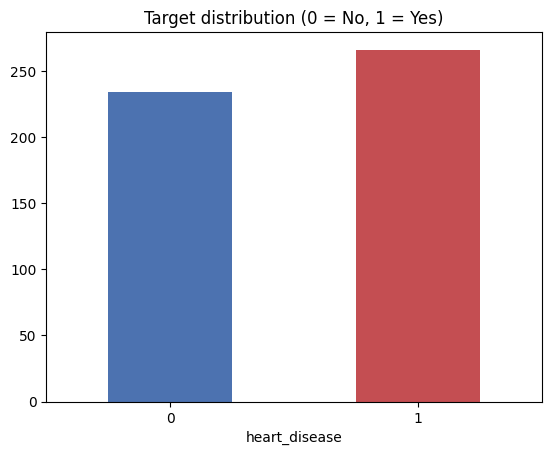

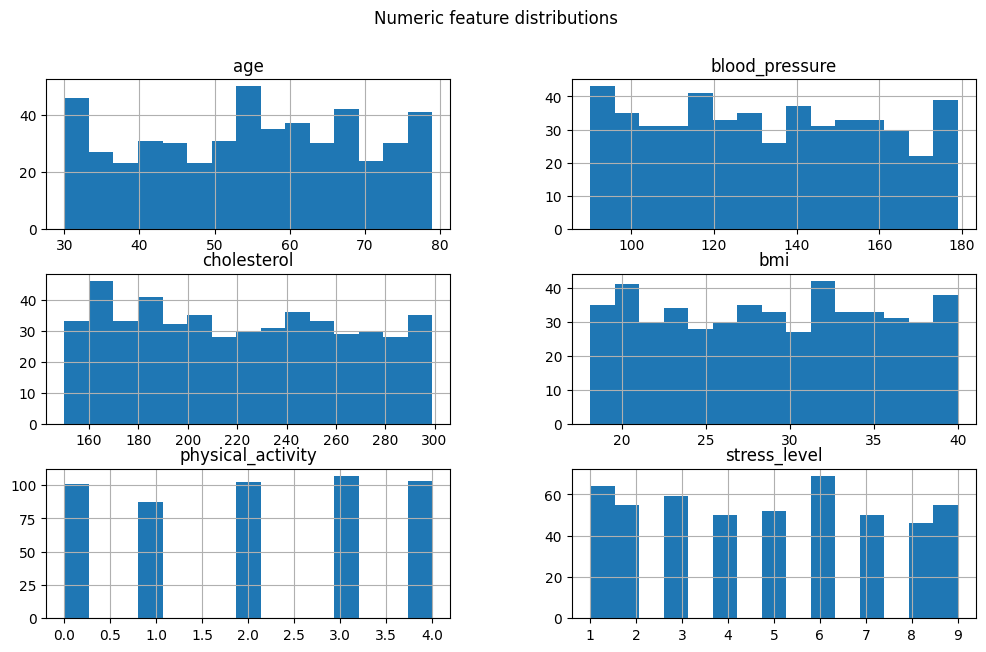

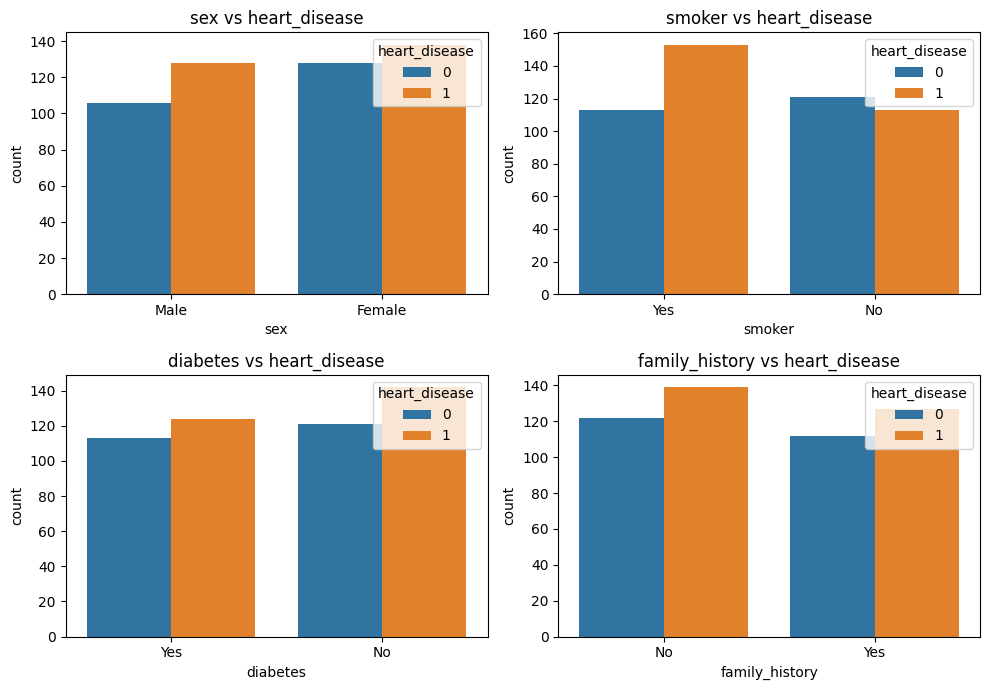

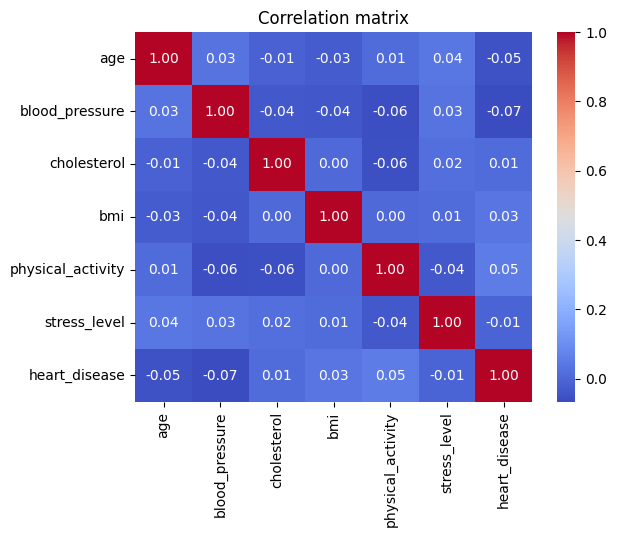

In [135]:
num_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'physical_activity', 'stress_level']
cat_cols = ['sex', 'smoker', 'diabetes', 'family_history']

df[TARGET].value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.title('Target distribution (0 = No, 1 = Yes)'); plt.xticks(rotation=0); plt.show()

df[num_cols].hist(bins=15, figsize=(12, 7)); plt.suptitle('Numeric feature distributions'); plt.show()

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, c in zip(ax.ravel(), cat_cols):
    sns.countplot(data=df, x=c, hue=TARGET, ax=a); a.set_title(f'{c} vs {TARGET}')
plt.tight_layout(); plt.show()

sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation matrix'); plt.show()

In [136]:
# How strongly does each feature relate to the target? (statistical tests)
rows = []
for c in num_cols:
    r, p = stats.pointbiserialr(df[TARGET], df[c]); rows.append([c, 'numeric', round(r, 3), round(p, 3)])
for c in cat_cols:
    p = stats.chi2_contingency(pd.crosstab(df[c], df[TARGET]))[1]; rows.append([c, 'categorical', None, round(p, 3)])
pd.DataFrame(rows, columns=['feature', 'type', 'correlation_with_target', 'p_value']).set_index('feature')

,type,correlation_with_target,p_value
feature,,,
age,numeric,-0.052,0.248
blood_pressure,numeric,-0.067,0.134
cholesterol,numeric,0.009,0.842
bmi,numeric,0.034,0.450
physical_activity,numeric,0.051,0.251
stress_level,numeric,-0.006,0.890
sex,categorical,NaN,0.588
smoker,categorical,NaN,0.048
diabetes,categorical,NaN,0.776


### 2. Preprocessing with OneHotEncoder

In [137]:
X = df.drop(columns=TARGET)
y = df[TARGET]

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
preprocessor.fit(X_train)
print(preprocessor.get_feature_names_out())

(400, 10) (100, 10)
['cat__sex_Female' 'cat__sex_Male' 'cat__smoker_No' 'cat__smoker_Yes'
 'cat__diabetes_No' 'cat__diabetes_Yes' 'cat__family_history_No'
 'cat__family_history_Yes' 'num__age' 'num__blood_pressure'
 'num__cholesterol' 'num__bmi' 'num__physical_activity'
 'num__stress_level']


### 3. Train models

In [138]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
pipes, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)]).fit(X_train, y_train)
    pipes[name] = pipe
    p = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, p), 'Precision': precision_score(y_test, p),
                 'Recall': recall_score(y_test, p), 'F1': f1_score(y_test, p),
                 'ROC-AUC': roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.56,0.562,0.774,0.651,0.505
Random Forest,0.50,0.529,0.509,0.519,0.512


### 4. Evaluation

==== Logistic Regression
              precision    recall  f1-score   support

  No disease       0.56      0.32      0.41        47
     Disease       0.56      0.77      0.65        53

    accuracy                           0.56       100
   macro avg       0.56      0.55      0.53       100
weighted avg       0.56      0.56      0.54       100

==== Random Forest
              precision    recall  f1-score   support

  No disease       0.47      0.49      0.48        47
     Disease       0.53      0.51      0.52        53

    accuracy                           0.50       100
   macro avg       0.50      0.50      0.50       100
weighted avg       0.50      0.50      0.50       100



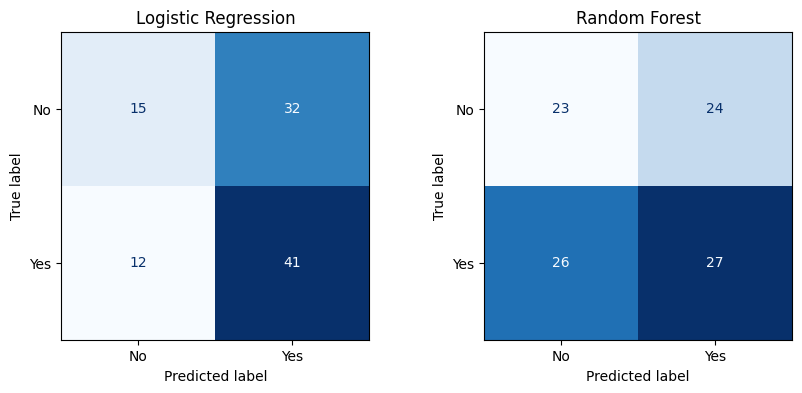

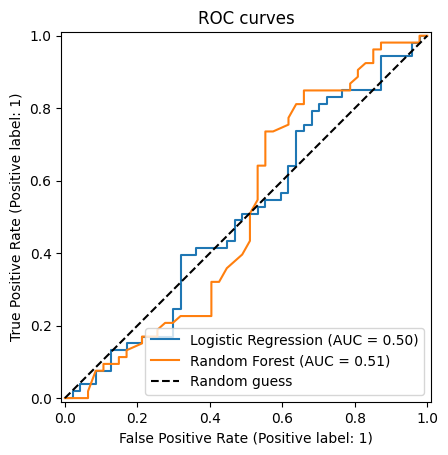

In [139]:
for name, pipe in pipes.items():
    print('====', name)
    print(classification_report(y_test, pipe.predict(X_test), target_names=['No disease', 'Disease']))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, pipe) in zip(ax, pipes.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)),
                           display_labels=['No', 'Yes']).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(name)
plt.show()

fig, ax = plt.subplots()
for name, pipe in pipes.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], 'k--', label='Random guess'); ax.legend(); ax.set_title('ROC curves'); plt.show()

In [140]:
# Robust check: repeated 5-fold CV on ALL data (a 100-row test set is noisy) and a shuffled-label baseline.
# If the real AUC is no better than the shuffled-label AUC, the features carry no usable signal.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
y_shuffled = y.sample(frac=1, random_state=1).values
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    real = cross_val_score(pipe, X, y, cv=cv, scoring='roc_auc')
    fake = cross_val_score(pipe, X, y_shuffled, cv=cv, scoring='roc_auc')
    print(f'{name:20s} CV ROC-AUC = {real.mean():.3f} (+/- {real.std():.3f})   | shuffled labels = {fake.mean():.3f}')

Logistic Regression  CV ROC-AUC = 0.508 (+/- 0.046)   | shuffled labels = 0.484
Random Forest        CV ROC-AUC = 0.507 (+/- 0.054)   | shuffled labels = 0.533


### 5. Save the model for the web app

In [141]:
best_name = results['ROC-AUC'].idxmax()
final = Pipeline([('prep', preprocessor), ('clf', models[best_name])]).fit(X, y)   # refit on all data for deployment
joblib.dump(final, 'model.pkl')
print('Saved model.pkl using:', best_name)

Saved model.pkl using: Random Forest


## Interpretation (write this in your own words)
- What do the test-set metrics and the CV ROC-AUC say about how well the model separates the classes?
- Compare the real CV AUC with the shuffled-label AUC. What does that tell you about the features?
- Which error matters more clinically (false negative vs false positive)?
- Limitations: dataset size, whether the data is real or synthetic, no external validation. State clearly that the app is an educational demo, not a diagnostic tool.